# Activity 2 - Text Classification with LSTM

LSTM Model

In [ ]:
import torch
import torch.nn as nn

class LSTMClassifier(nn.Module):

    def __init__(self, vocab_size):
        super().__init__()

        # Embedding layer
        self.embedding = nn.Embedding(
            vocab_size,
            128,
            padding_idx=PAD_ID
        )

        # LSTM layer
        self.lstm = nn.LSTM(
            input_size=128,
            hidden_size=128,
            num_layers=2,
            batch_first=True,
            dropout=0.3,
            bidirectional=True
        )

        # Dropout
        self.dropout = nn.Dropout(0.4)

        # Linear output layer
        self.fc = nn.Linear(
            128 * 2,
            2
        )

    def forward(self, x):

        # Embedding
        x = self.embedding(x)

        # LSTM
        output, (hidden, cell) = self.lstm(x)

        # Last timestep
        x = output[:, -1, :]

        # Dropout
        x = self.dropout(x)

        # Classification
        x = self.fc(x)

        return x

Create the LSTM Model

In [ ]:
VOCAB_SIZE = encoding.n_vocab + 1

lstm_model = LSTMClassifier(
    VOCAB_SIZE
).to(device)

print(lstm_model)

LSTMClassifier(
  (embedding): Embedding(100278, 128, padding_idx=0)
  (lstm): LSTM(128, 128, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (dropout): Dropout(p=0.4, inplace=False)
  (fc): Linear(in_features=256, out_features=2, bias=True)
)


Loss Function and Optimizer

In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    lstm_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

Train the LSTM

In [ ]:
EPOCHS = 8

best_loss = float("inf")
patience = 2
counter = 0

for epoch in range(EPOCHS):

    lstm_model.train()

    total_loss = 0

    for batch_x, batch_y in train_loader:

        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        # Clear gradients
        optimizer.zero_grad()

        # Forward pass
        output = lstm_model(batch_x)

        # Calculate loss
        loss = criterion(output, batch_y)

        # Backpropagation
        loss.backward()

        # Prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(
            lstm_model.parameters(),
            max_norm=1.0
        )

        # Update weights
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} "
        f"- Training Loss: {avg_loss:.4f}"
    )

    # Save best model
    if avg_loss < best_loss:

        best_loss = avg_loss
        counter = 0

        torch.save(
            lstm_model.state_dict(),
            "best_lstm_model.pth"
        )

    else:

        counter += 1

        if counter >= patience:

            print("Early stopping...")
            break

Epoch 1/8 - Training Loss: 0.6864
Epoch 2/8 - Training Loss: 0.5747
Epoch 3/8 - Training Loss: 0.4306
Epoch 4/8 - Training Loss: 0.3227
Epoch 5/8 - Training Loss: 0.2498
Epoch 6/8 - Training Loss: 0.1873
Epoch 7/8 - Training Loss: 0.1276
Epoch 8/8 - Training Loss: 0.0813


Load Best LSTM Model

In [ ]:
lstm_model.load_state_dict(
    torch.load(
        "best_lstm_model.pth",
        map_location=device
    )
)

lstm_model.eval()

print("Best LSTM model loaded successfully.")

Best LSTM model loaded successfully.


Make Predictions on Test Set

In [ ]:
lstm_predictions = []
lstm_labels = []

lstm_model.eval()

with torch.no_grad():

    for batch_x, batch_y in test_loader:

        batch_x = batch_x.to(device)

        output = lstm_model(batch_x)

        predictions = torch.argmax(
            output,
            dim=1
        ).cpu().numpy()

        lstm_predictions.extend(predictions)
        lstm_labels.extend(batch_y.numpy())

print("LSTM predictions completed.")

LSTM predictions completed.


Accuracy, Precision, Recall and F1

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

lstm_accuracy = accuracy_score(
    lstm_labels,
    lstm_predictions
)

lstm_precision = precision_score(
    lstm_labels,
    lstm_predictions
)

lstm_recall = recall_score(
    lstm_labels,
    lstm_predictions
)

lstm_f1 = f1_score(
    lstm_labels,
    lstm_predictions
)

print("========== LSTM RESULTS ==========")
print(f"Accuracy : {lstm_accuracy:.4f}")
print(f"Precision: {lstm_precision:.4f}")
print(f"Recall   : {lstm_recall:.4f}")
print(f"F1 Score : {lstm_f1:.4f}")

========== LSTM RESULTS ==========
Accuracy : 0.8676
Precision: 0.8628
Recall   : 0.8759
F1 Score : 0.8693


Classification Report

In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        lstm_labels,
        lstm_predictions,
        target_names=[
            "Negative",
            "Positive"
        ]
    )
)

              precision    recall  f1-score   support

    Negative       0.87      0.86      0.87      1171
    Positive       0.86      0.88      0.87      1185

    accuracy                           0.87      2356
   macro avg       0.87      0.87      0.87      2356
weighted avg       0.87      0.87      0.87      2356



Confusion Matrix

In [ ]:
from sklearn.metrics import confusion_matrix

lstm_cm = confusion_matrix(
    lstm_labels,
    lstm_predictions
)

print("LSTM Confusion Matrix:")
print(lstm_cm)

LSTM Confusion Matrix:
[[1006  165]
 [ 147 1038]]


Visualize LSTM Confusion Matrix

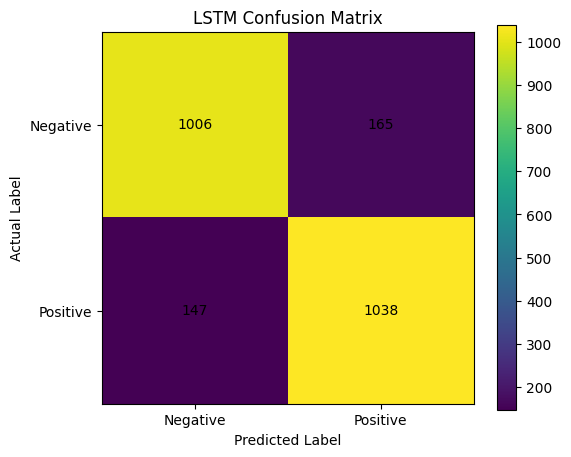

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))

plt.imshow(lstm_cm)

plt.title("LSTM Confusion Matrix")

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks(
    [0, 1],
    ["Negative", "Positive"]
)

plt.yticks(
    [0, 1],
    ["Negative", "Positive"]
)

for i in range(2):
    for j in range(2):

        plt.text(
            j,
            i,
            lstm_cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()

plt.show()

Same Custom Reviews

In [ ]:
new_reviews = [
    "This movie was absolutely fantastic and I loved every minute of it.",
    "The movie was boring, predictable and a complete waste of time.",
    "The acting was excellent and the story was very enjoyable."
]

LSTM Prediction Function

In [ ]:
def predict_lstm_sentiment(text):

    tokens = encoding.encode(text)

    tokens = tokens[:MAX_LEN]

    tokens = [token + 1 for token in tokens]

    tokens += [PAD_ID] * (
        MAX_LEN - len(tokens)
    )

    tensor = torch.tensor(
        [tokens],
        dtype=torch.long
    ).to(device)

    lstm_model.eval()

    with torch.no_grad():

        output = lstm_model(tensor)

        prediction = torch.argmax(
            output,
            dim=1
        ).item()

    if prediction == 1:
        return "Positive"
    else:
        return "Negative"

Test Custom Reviews

In [ ]:
print("====== LSTM CUSTOM PREDICTIONS ======")

for review in new_reviews:

    prediction = predict_lstm_sentiment(review)

    print("\nReview:", review)
    print("LSTM Prediction:", prediction)

====== LSTM CUSTOM PREDICTIONS ======

Review: This movie was absolutely fantastic and I loved every minute of it.
LSTM Prediction: Positive

Review: The movie was boring, predictable and a complete waste of time.
LSTM Prediction: Negative

Review: The acting was excellent and the story was very enjoyable.
LSTM Prediction: Positive


Compare RNN vs LSTM

In [ ]:
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],

    "RNN": [
        accuracy,
        precision,
        recall,
        f1
    ],

    "LSTM": [
        lstm_accuracy,
        lstm_precision,
        lstm_recall,
        lstm_f1
    ]
})

comparison

,Metric,RNN,LSTM
0,Accuracy,0.622241,0.867572
1,Precision,0.627927,0.862843
2,Recall,0.610970,0.875949
3,F1 Score,0.619333,0.869347


Percentage Comparison

In [ ]:
print("========== RNN vs LSTM ==========")

print(
    f"Accuracy  -> RNN: {accuracy:.4f} | "
    f"LSTM: {lstm_accuracy:.4f}"
)

print(
    f"Precision -> RNN: {precision:.4f} | "
    f"LSTM: {lstm_precision:.4f}"
)

print(
    f"Recall    -> RNN: {recall:.4f} | "
    f"LSTM: {lstm_recall:.4f}"
)

print(
    f"F1 Score  -> RNN: {f1:.4f} | "
    f"LSTM: {lstm_f1:.4f}"
)

========== RNN vs LSTM ==========
Accuracy  -> RNN: 0.6222 | LSTM: 0.8676
Precision -> RNN: 0.6279 | LSTM: 0.8628
Recall    -> RNN: 0.6110 | LSTM: 0.8759
F1 Score  -> RNN: 0.6193 | LSTM: 0.8693


Compare Custom Predictions

In [ ]:
print("========== CUSTOM REVIEW COMPARISON ==========")

for review in new_reviews:

    rnn_prediction = predict_sentiment(review)
    lstm_prediction = predict_lstm_sentiment(review)

    print("\nReview:", review)
    print("RNN :", rnn_prediction)
    print("LSTM:", lstm_prediction)

========== CUSTOM REVIEW COMPARISON ==========

Review: This movie was absolutely fantastic and I loved every minute of it.
RNN : Positive
LSTM: Positive

Review: The movie was boring, predictable and a complete waste of time.
RNN : Negative
LSTM: Negative

Review: The acting was excellent and the story was very enjoyable.
RNN : Negative
LSTM: Positive


### 1. Which model achieved higher test accuracy — RNN or LSTM?

The **LSTM model achieved higher test accuracy** than the RNN model.

- **RNN Accuracy:** 62.22%
- **LSTM Accuracy:** 86.76%

Therefore, the LSTM performed significantly better, with an improvement of approximately **24.54 percentage points** over the RNN.

The LSTM also achieved better results for the other evaluation metrics:

- **Precision:** RNN = 62.79%, LSTM = 86.28%
- **Recall:** RNN = 61.10%, LSTM = 87.59%
- **F1 Score:** RNN = 61.93%, LSTM = 86.93%

Hence, the LSTM provided substantially better overall sentiment classification performance.


### 2. Did the LSTM reach a lower training loss than the RNN, or in fewer epochs?

Yes. The LSTM reached a much lower training loss than the RNN within the same **8 epochs**.

The RNN training loss decreased from **0.6996** in Epoch 1 to **0.6225** in Epoch 8.

The LSTM training loss decreased from **0.6864** in Epoch 1 to only **0.0813** in Epoch 8.

Therefore, the LSTM achieved a substantially lower training loss than the RNN. Both models were trained for 8 epochs, so the LSTM did not require fewer epochs in this experiment; instead, it learned much more effectively during the same number of epochs.


### 3. Did the RNN and LSTM agree on the predictions for your custom test sentences? If not, which one seems more reliable?

The RNN and LSTM agreed on **2 out of 3** custom review predictions.

| Review | RNN | LSTM |
|---|---|---|
| "This movie was absolutely fantastic and I loved every minute of it." | Positive | Positive |
| "The movie was boring, predictable and a complete waste of time." | Negative | Negative |
| "The acting was excellent and the story was very enjoyable." | Negative | Positive |

The models disagreed on the third review. The **LSTM prediction of Positive appears more reliable** because the review contains clearly positive expressions such as "excellent" and "very enjoyable."

This is also consistent with the LSTM's much higher test accuracy, precision, recall, and F1-score compared with the RNN.


### 4. Based on this exercise, what is the LSTM doing differently from the RNN that could explain any difference in results?

The LSTM is designed to handle long-term dependencies in sequential data more effectively than a standard RNN. It uses a memory cell and gating mechanisms to control what information should be **retained, updated, and forgotten** while processing the sequence.

A standard RNN can have difficulty retaining important information from earlier parts of a long review because of problems such as vanishing gradients. This can make it harder to understand sentiment when important words or phrases occur far apart in the review.

The LSTM's gating mechanism helps preserve relevant information for longer sequences and discard information that is less useful. This can explain why the LSTM achieved much better results in this experiment.

In our experiment, this difference is clearly reflected in the results:

- RNN Accuracy = **62.22%**
- LSTM Accuracy = **86.76%**
- RNN Training Loss = **0.6225**
- LSTM Training Loss = **0.0813**

Thus, the LSTM was able to learn the sentiment patterns in the movie reviews much more effectively than the RNN.